# Лабораторная работа №2

ФИО: Григорьев Владислав Алексеевич
Группа: БИВТ-24-СП-4

Отправлять можно следующими способами:
1. Запушить этот ноутбук в GitHub в репозиторий, где у вас лежат ноутбуки с лабами

Deadlines:
- Занятие №6

Что необходимо сделать:  
**В общих чертах просто провести EDA** (но обычно это не бывает просто)
## Читайте задание внимательно

Исходные данные:
1. В [табличке](https://docs.google.com/spreadsheets/d/1NOE0D4JQgD6LbvUqWboUI1TFj4P87ugbqUTDquxlGEI/edit?usp=sharing) необходимо узнать название своего датасета 
2. Скачать нужны вам данные можно в [Google Drive](https://drive.google.com/drive/folders/1sbsjBsJ_ln0XgXCI9R6s17pvyvApgcwF?usp=sharing)
  
---
Теперь по пунктам, что я от вас жду:  
1. **Найти** в таблице (из исходных данных) название своего датасета
2. **Описать** кратко постановку задачи, что от вас хотят. Какие есть переменные. Целевое событие непрерывно (предсказываем число от -$\infty$ до $\infty$) либо дискретно (предсказываем класс из конечного множества вариантов, например 0 или 1, или какое-то число в диапазоне [0; 10])
3. Построить распределение целевой переменной в виде гистограммы, сделать промежуточные выводы (обратите внимание на однородоность распределения и возможный дисбаланс). Посчитайте количество уникальных значений целевой переменной.
4. Выведите основные статистики по переменным в датасете (для этого есть готовый метод в pandas, он считает count, min, max, mean, 25%, 50% и пр.). Это делается **одним** методом (вы его знаете).
5. Выведите основную информацию по датасету (сколько всего колонок, каких они типов, сколько в них non-null элементов). Это делается **одним** методом (вы его знаете).
6. Посчитайте количество пропусков (NaN, Null, null, None) элементов во всех колонках. Предположите, почему эти пропуски могли возникнуть, и как их можно было бы заменить. 
7. Постройте гистограммы 5 любых признаков (из множества `X`, или как оно изначально у нас называется `data.data`). Если видите какое-то смещение, несимметричность и прочее, опишите это словами в ноутбуке.
8. Постройте графики зависимости 5 любых (на ваш выбор) переменных от целевой переменной (если переменных меньше, чем 5, то сделайте столько, сколько получится). Сделайте вывод, можно ли использовать эти переменные для прогнозирования целевой переменной (иначе говоря, есть ли какая-то взаимосвязь между y-переменной и X-переменной)  
9. _extra_ (необязательно). Посмотрите на зависимость двух переменных одновременно от целевой переменной. То есть по оси OX должна быть переменная $X_{n}$, по оси OY -- переменная $X_{k}$. И у вас будет две кривые (два облака точек) в разрезе целевой переменной. Либо вы можете построить похожее для категориальных признаков, но необходимо будет прочитать про heatmap. 

---
P.S.  
Просьба -- делать каждое задание в отдельных ячейках и с отдельными заголовками (как пункт 1 и 2 в этом ноутбуке) типа  
- Заголовок
- Ячейки с кодом
- Другой заголовок
- Другие ячейки с кодом

## 0. Пример импорта данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

# keep_default_na=False — чтобы pandas не превращал строку 'None' в Sleep Disorder в NaN,
# т.к. 'None' здесь — валидный класс «нет расстройства сна», а не пропуск.
data = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv', keep_default_na=False)
data.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


## 1. Название датасета

В таблице с вариантами мой датасет — **Sleep Health and Lifestyle Dataset**.

Датасет описывает образ жизни, сон и состояние здоровья 374 человек, содержит 13 колонок:
- `Person ID` — идентификатор записи (служебный);
- `Gender`, `Age`, `Occupation` — демографические признаки;
- `Sleep Duration`, `Quality of Sleep` — характеристики сна;
- `Physical Activity Level`, `Stress Level`, `Daily Steps` — образ жизни;
- `BMI Category`, `Blood Pressure`, `Heart Rate` — медицинские показатели;
- `Sleep Disorder` — целевая переменная.

## 2. Описание постановки задачи

In [2]:
"""
2. Описание постановки задачи.

Датасет: Sleep Health and Lifestyle Dataset (374 записи, 13 колонок).

Задача: классификация в дискретной постановке — по данным об образе жизни
и физиологических показателях человека предсказать наличие и тип
расстройства сна.

Целевая переменная — Sleep Disorder, три класса:
- None         — нет расстройства (~58% записей);
- Sleep Apnea  — апноэ во сне (~21%);
- Insomnia     — бессонница (~21%).

Признаки (X):
- числовые:       Age, Sleep Duration, Quality of Sleep, Physical Activity Level,
                  Stress Level, Heart Rate, Daily Steps;
- категориальные: Gender, Occupation, BMI Category;
- составной:      Blood Pressure (строка вида "126/83" — можно разбить на
                  два числовых признака: систолическое и диастолическое давление);
- Person ID — служебный идентификатор, в модель не пойдёт.
"""

print('Целевая переменная:', 'Sleep Disorder')
print('Классы:', sorted(data['Sleep Disorder'].unique()))
print()
print('Распределение:')
print(data['Sleep Disorder'].value_counts())

Целевая переменная: Sleep Disorder
Классы: ['Insomnia', 'None', 'Sleep Apnea']

Распределение:
Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64


## 3. Распределение целевой переменной

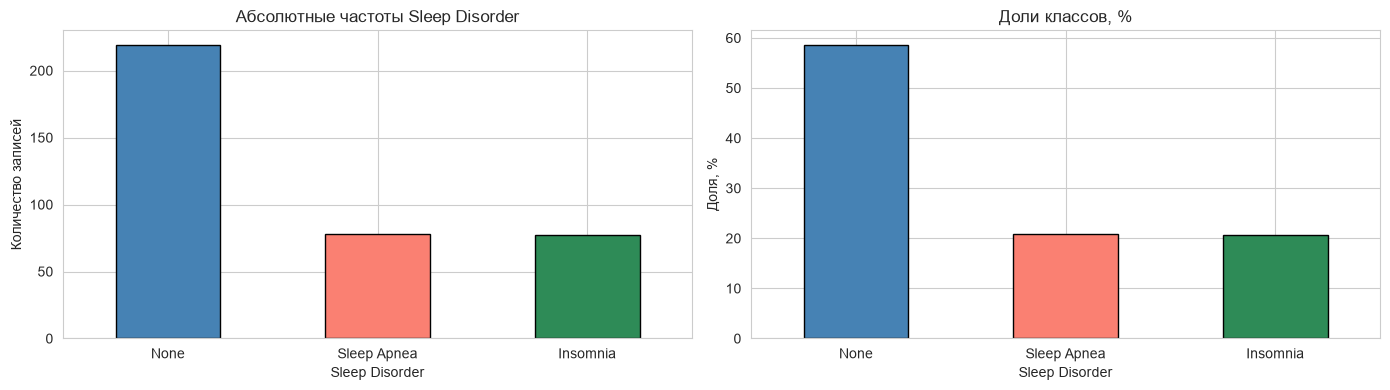

Уникальных значений целевой переменной: 3

Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64


In [3]:
order = ['None', 'Sleep Apnea', 'Insomnia']
counts = data['Sleep Disorder'].value_counts().reindex(order)
shares = (counts / counts.sum() * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

counts.plot(kind='bar', ax=axes[0], color=['steelblue', 'salmon', 'seagreen'], edgecolor='black')
axes[0].set_title('Абсолютные частоты Sleep Disorder')
axes[0].set_ylabel('Количество записей')
axes[0].tick_params(axis='x', rotation=0)

shares.plot(kind='bar', ax=axes[1], color=['steelblue', 'salmon', 'seagreen'], edgecolor='black')
axes[1].set_title('Доли классов, %')
axes[1].set_ylabel('Доля, %')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

print('Уникальных значений целевой переменной:', data['Sleep Disorder'].nunique())
print()
print(data['Sleep Disorder'].value_counts())

**Вывод по распределению:**
- Класс `None` доминирует — примерно 58% записей.
- Классы `Sleep Apnea` и `Insomnia` примерно равны — по ~21% каждый.
- Распределение **неоднородное**, наблюдается заметный дисбаланс классов. При обучении моделей это стоит учитывать: использовать `class_weight='balanced'`, стратифицированное разбиение train/test и метрики вроде F1-macro вместо accuracy.
- Уникальных значений в целевой переменной — **3**.

## 4. Основные статистики по переменным

In [4]:
data.describe(include='all')

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
count,374.000000,374,374.000000,374,374.000000,374.000000,374.000000,374.000000,374,374,374.000000,374.000000,374
unique,NaN,2,NaN,11,NaN,NaN,NaN,NaN,4,25,NaN,NaN,3
top,NaN,Male,NaN,Nurse,NaN,NaN,NaN,NaN,Normal,130/85,NaN,NaN,None
freq,NaN,189,NaN,73,NaN,NaN,NaN,NaN,195,99,NaN,NaN,219
mean,187.500000,NaN,42.184492,NaN,7.132086,7.312834,59.171123,5.385027,NaN,NaN,70.165775,6816.844920,NaN
std,108.108742,NaN,8.673133,NaN,0.795657,1.196956,20.830804,1.774526,NaN,NaN,4.135676,1617.915679,NaN
min,1.000000,NaN,27.000000,NaN,5.800000,4.000000,30.000000,3.000000,NaN,NaN,65.000000,3000.000000,NaN
25%,94.250000,NaN,35.250000,NaN,6.400000,6.000000,45.000000,4.000000,NaN,NaN,68.000000,5600.000000,NaN
50%,187.500000,NaN,43.000000,NaN,7.200000,7.000000,60.000000,5.000000,NaN,NaN,70.000000,7000.000000,NaN
75%,280.750000,NaN,50.000000,NaN,7.800000,8.000000,75.000000,7.000000,NaN,NaN,72.000000,8000.000000,NaN


## 5. Основная информация по датасету

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    str    
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    str    
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    str    
 9   Blood Pressure           374 non-null    str    
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           374 non-null    str    
dtypes: float64(1), int64(7), str(5)
memory usage: 38.1 KB


## 6. Пропуски в данных

In [6]:
data.isnull().sum()

Person ID                  0
Gender                     0
Age                        0
Occupation                 0
Sleep Duration             0
Quality of Sleep           0
Physical Activity Level    0
Stress Level               0
BMI Category               0
Blood Pressure             0
Heart Rate                 0
Daily Steps                0
Sleep Disorder             0
dtype: int64

**Вывод по пропускам:**
- Реальных пропусков (NaN) в датасете **нет** ни в одной колонке.
- Важный нюанс: при стандартной загрузке `pd.read_csv` pandas по умолчанию интерпретирует строку `"None"` в колонке `Sleep Disorder` как NaN (эта строка входит в список `keep_default_na`). Это было бы ошибкой — `None` здесь **валидный класс** «нет расстройства», а не отсутствие значения. Поэтому при загрузке мы используем `keep_default_na=False`.
- Если бы пропуски были: числовые признаки (`Age`, `Heart Rate` и т.п.) можно было бы заполнять медианой (устойчиво к выбросам), категориальные (`Occupation`, `BMI Category`) — модой или отдельной категорией `"Unknown"`. В нашем случае это не требуется.

## 7. Гистограммы 5 признаков

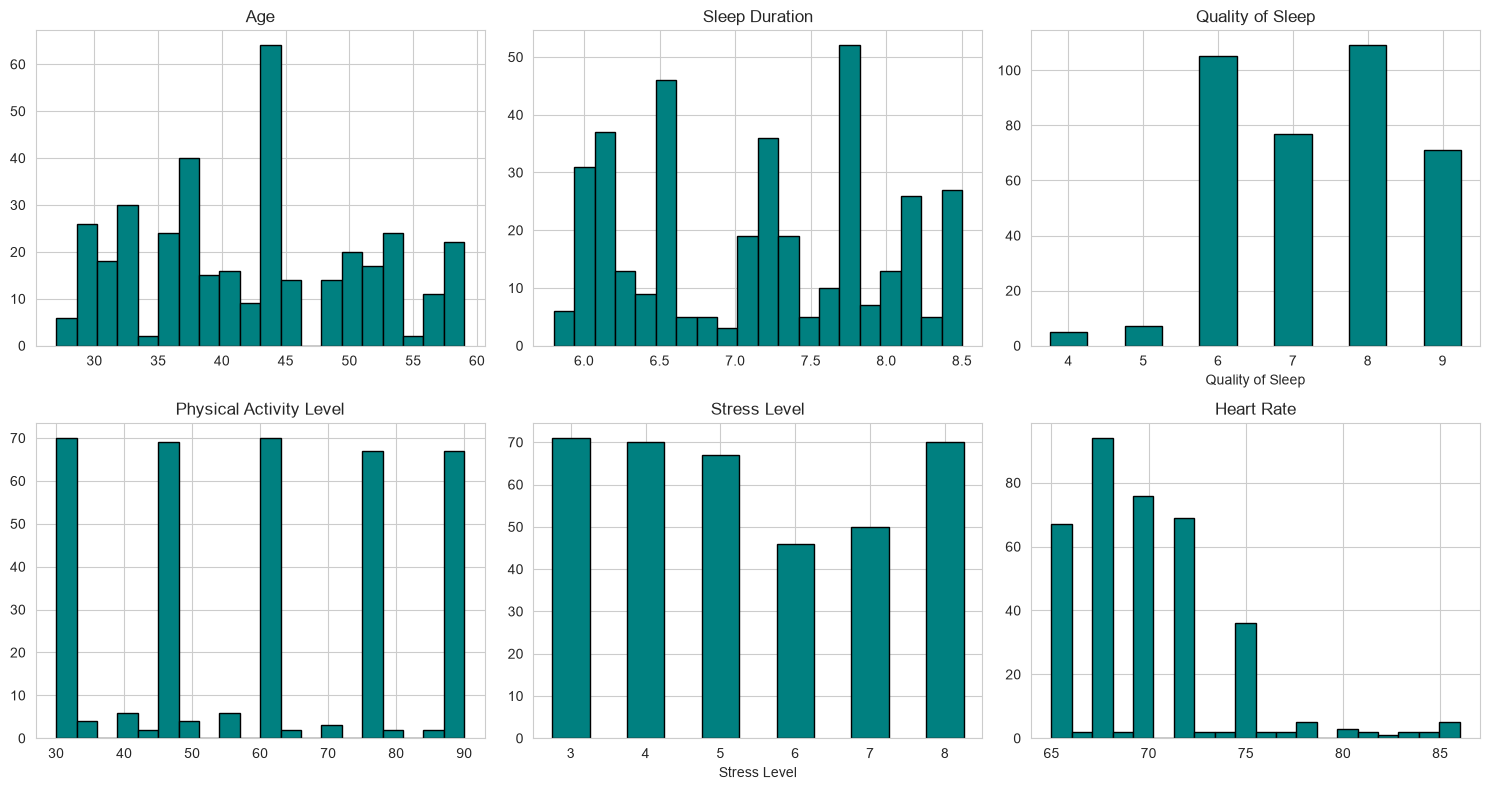

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

data['Age'].hist(ax=axes[0], bins=20, color='teal', edgecolor='black')
axes[0].set_title('Age')

data['Sleep Duration'].hist(ax=axes[1], bins=20, color='teal', edgecolor='black')
axes[1].set_title('Sleep Duration')

data['Quality of Sleep'].value_counts().sort_index().plot(
    kind='bar', ax=axes[2], color='teal', edgecolor='black')
axes[2].set_title('Quality of Sleep')
axes[2].tick_params(axis='x', rotation=0)

data['Physical Activity Level'].hist(ax=axes[3], bins=20, color='teal', edgecolor='black')
axes[3].set_title('Physical Activity Level')

data['Stress Level'].value_counts().sort_index().plot(
    kind='bar', ax=axes[4], color='teal', edgecolor='black')
axes[4].set_title('Stress Level')
axes[4].tick_params(axis='x', rotation=0)

data['Heart Rate'].hist(ax=axes[5], bins=20, color='teal', edgecolor='black')
axes[5].set_title('Heart Rate')

plt.tight_layout()
plt.show()

**Вывод по распределениям признаков:**
- `Age` — правосторонняя асимметрия: большинство людей в возрасте 30–45 лет, но есть «хвост» до ~60.
- `Sleep Duration` — бимодальное: заметны пики около 6 и 8 часов, значений «где-то посередине» относительно мало.
- `Quality of Sleep` — дискретная шкала 4–9, распределение скошено к высоким значениям (большинство оценивает сон на 7–8).
- `Physical Activity Level` — мультимодальное, пики на «круглых» значениях (30, 45, 60, 75, 90) — типично для анкетных данных.
- `Stress Level` — дискретная шкала 3–8, скошена вправо.
- `Heart Rate` — распределение близко к нормальному с небольшим правым хвостом.

## 8. Зависимость 5 переменных от целевой переменной

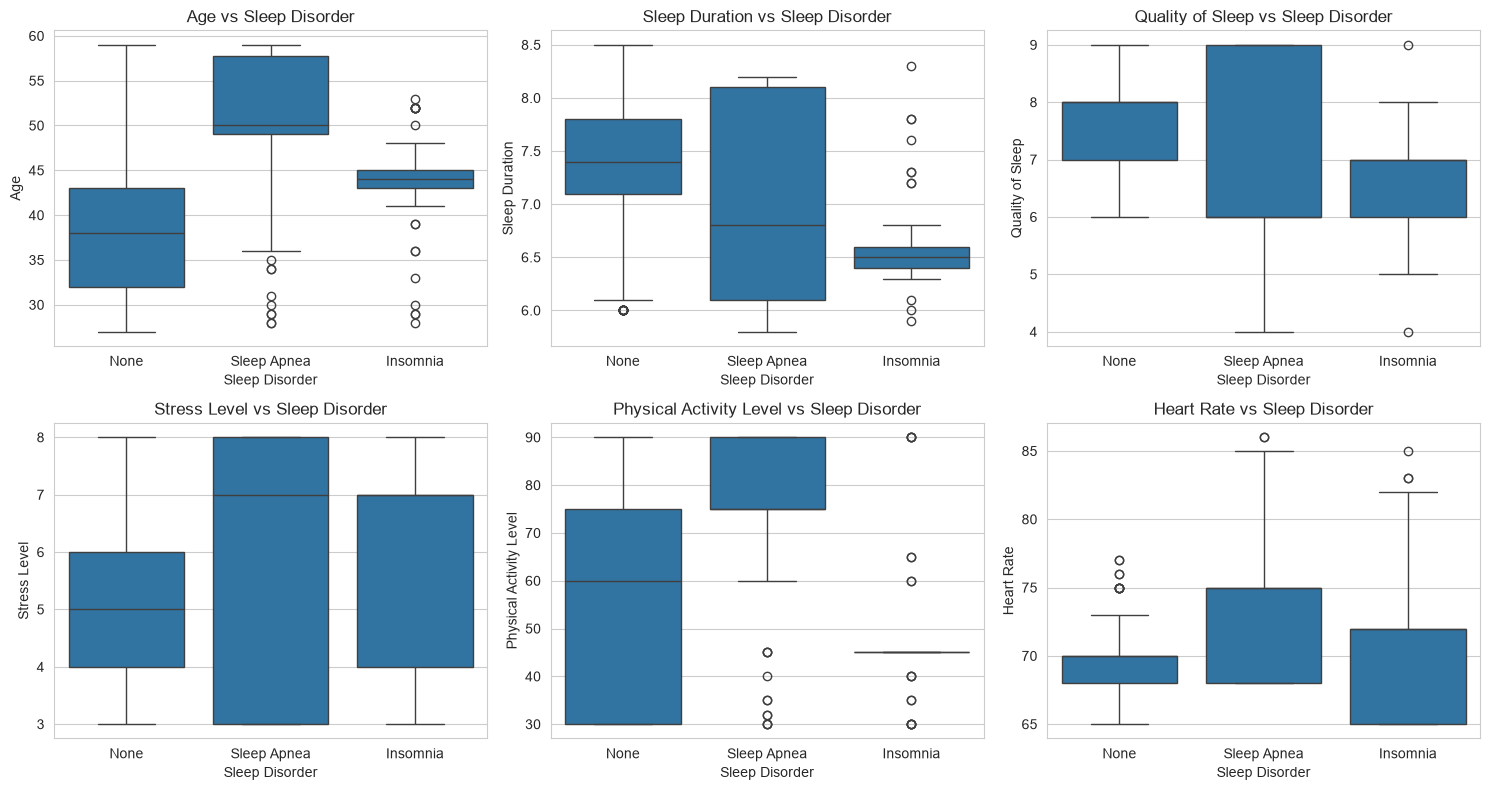

In [8]:
plot_cols = ['Age', 'Sleep Duration', 'Quality of Sleep',
             'Stress Level', 'Physical Activity Level', 'Heart Rate']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for i, col in enumerate(plot_cols):
    sns.boxplot(data=data, x='Sleep Disorder', y=col,
                order=['None', 'Sleep Apnea', 'Insomnia'], ax=axes[i])
    axes[i].set_title(f'{col} vs Sleep Disorder')
    axes[i].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

**Вывод по зависимости от целевой переменной:**

- `Sleep Duration` — средние у `None` (7.36) и `Sleep Apnea` (7.03) близки, ящики сильно пересекаются; у `Insomnia` среднее заметно ниже (6.59). Признак полезен, но основной сигнал здесь отличает `Insomnia` от двух других классов, а не `Sleep Apnea` от `None`.
- `Quality of Sleep` — самый высокий у `None` (7.63), чуть ниже у `Sleep Apnea` (7.21), явно ниже у `Insomnia` (6.53). Хорошо отделяет `Insomnia`.
- `Stress Level` — у `Insomnia` (5.87) выше, чем у `None` (5.11) и `Sleep Apnea` (5.67). Полезен в первую очередь как маркер бессонницы.
- `Age` — у `Sleep Apnea` существенно выше (49.7), чем у `None` (39.0) и `Insomnia` (43.5). Один из самых «разделяющих» признаков именно для `Sleep Apnea`.
- `Physical Activity Level` — сильно варьирует между классами: `Sleep Apnea` (74.79) > `None` (57.95) > `Insomnia` (46.82). Признак информативен, но интерпретировать нужно осторожно — среди `Sleep Apnea` в выборке много медсестёр с высоким уровнем активности по работе, а не «по желанию».
- `Heart Rate` — у `Sleep Apnea` (73.1) чуть выше, чем у `None` (69.0) и `Insomnia` (70.5). Слабый, но ненулевой сигнал.

Общий вывод: лучше всего различают классы `Age` (для `Sleep Apnea`), `Stress Level` и `Quality of Sleep` (для `Insomnia`), а `Sleep Duration` работает как «отделитель `Insomnia` от остальных». Класс `Sleep Apnea` в этом датасете — самый «неоднородный»: среди его представителей есть и люди с нормальным сном, и с явно плохим, поэтому простой порог по `Sleep Duration` для него не сработает.

## 9. Extra: зависимость двух переменных от целевой

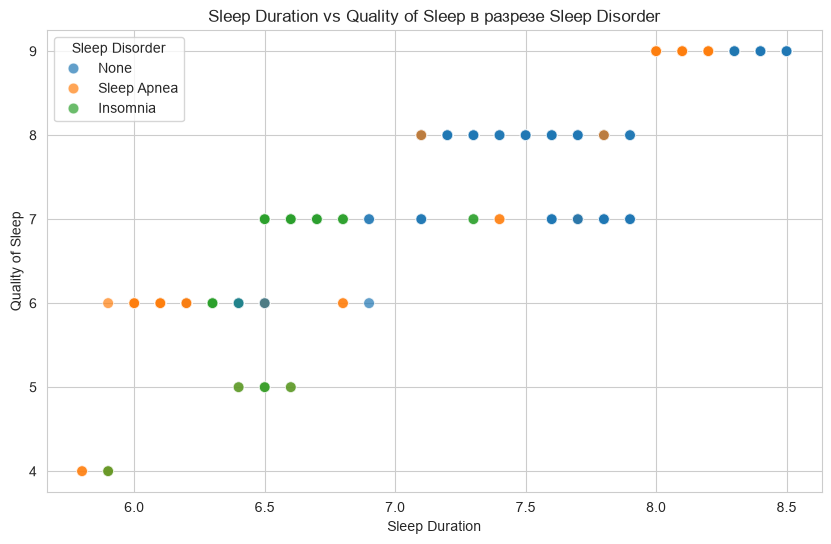

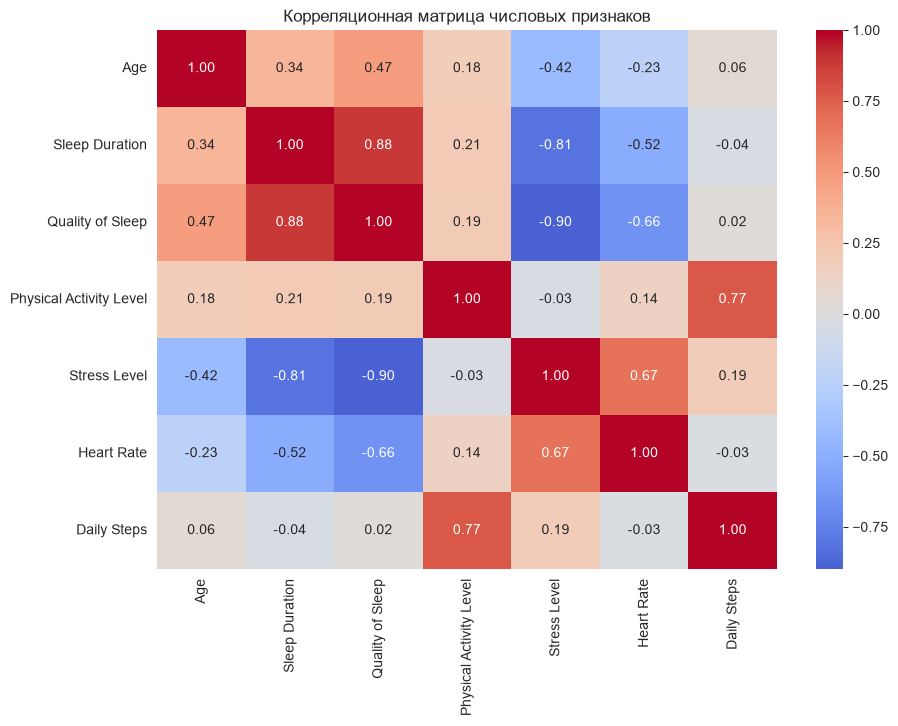

Средние значения признаков по классам Sleep Disorder:


,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
Sleep Disorder,,,,,,,
Insomnia,43.52,6.59,6.53,46.82,5.87,70.47,5901.30
None,39.04,7.36,7.63,57.95,5.11,69.02,6852.97
Sleep Apnea,49.71,7.03,7.21,74.79,5.67,73.09,7619.23


In [9]:
# 1) Диаграмма рассеяния: две переменные в разрезе целевой
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data, x='Sleep Duration', y='Quality of Sleep',
                hue='Sleep Disorder', hue_order=['None', 'Sleep Apnea', 'Insomnia'],
                alpha=0.7, s=60)
plt.title('Sleep Duration vs Quality of Sleep в разрезе Sleep Disorder')
plt.show()

# 2) Корреляционная матрица числовых признаков
num_cols = ['Age', 'Sleep Duration', 'Quality of Sleep',
            'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps']

plt.figure(figsize=(10, 7))
sns.heatmap(data[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляционная матрица числовых признаков')
plt.show()

# 3) Средние значения признаков по классам
print('Средние значения признаков по классам Sleep Disorder:')
data.groupby('Sleep Disorder')[num_cols].mean().round(2)

**Вывод (extra):**
- На диаграмме рассеяния `Sleep Duration` vs `Quality of Sleep` классы образуют компактные кластеры: `None` — правый верхний угол (долгий и качественный сон), `Insomnia` и `Sleep Apnea` — нижняя-левая часть. Признаки хорошо разделяют классы в паре.
- По heatmap: `Sleep Duration` и `Quality of Sleep` сильно коррелируют между собой (r ≈ 0.88) — при построении линейных моделей один из этих признаков имеет смысл убрать, чтобы снизить мультиколлинеарность. Аналогично `Daily Steps` и `Physical Activity Level` сильно связаны.
- Группировка по классам подтверждает выводы из п. 8: у `None` самые высокие средние `Sleep Duration` и `Quality of Sleep`, у `Insomnia` — самый высокий `Stress Level`.